# MSC barycenter evaluation & sparsification

Load a **complete** (pre-threshold) barycenter bundle saved by `msc_barycenter_shortestpath.ipynb` or `msc_barycenter_lambda_converge.ipynb`, then:

1. **Held-out FPGW representativeness** of the attributed measure-network barycenter (learned relation), with a paired skeleton shortest-path variant.
2. **Held-out edge-evidence Brier skill** of transported input adjacency (occurrence × adjacency), with a reliability diagram.
3. **Morse-valid evidence retention**: fraction of evidence-weighted curve length that can coexist in one geometrically and combinatorially plausible Morse graph.
4. Threshold edges at several `EDGE_FRACTION_PCT` values and score PFGW quality vs a seed baseline.
5. Attribute-alignment diagnostics under significant couplings.
6. Edge-density NMS sparsification of a chosen thresholded graph.

Shared helpers: `lib/msc_barycenter_eval.py`, `lib/msc_barycenter_threshold.py`, `lib/msc_plotting.py`, `lib/graph_sparsify.py`, `lib/barycenter_io.py`.


In [14]:
# Imports
import importlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import lib.barycenter_io as barycenter_io
import lib.gromov as gromov
import lib.gromov_barycenter as gromov_barycenter
import lib.msc_barycenter_eval as msc_barycenter_eval
import lib.msc_barycenter_threshold as msc_barycenter_threshold
import lib.msc_plotting as msc_plotting
import lib.graph_sparsify as graph_sparsify

importlib.reload(barycenter_io)
importlib.reload(gromov)
importlib.reload(gromov_barycenter)
importlib.reload(msc_barycenter_threshold)
importlib.reload(msc_barycenter_eval)
importlib.reload(msc_plotting)
importlib.reload(graph_sparsify)

from lib.barycenter_io import (
    load_barycenter_bundle,
    resolve_eval_seed,
    list_barycenter_bundles,
    print_barycenter_bundle_menu,
    select_barycenter_bundle,
)
from lib.msc_barycenter_eval import (
    evaluate_seed_network,
    evaluate_thresholded_barycenter,
    attribute_alignment_for_eval_results,
    summarize_attribute_alignment_distributions,
    plot_attribute_alignment_boxplots,
    mean_transported_mass_fraction,
    mpfgw_pairwise_costs,
    loo_pfgw_barycenters,
    held_out_fpgw_representativeness,
    plot_held_out_representativeness,
    compute_held_out_edge_brier,
    plot_edge_brier_reliability,
    plot_edge_brier_error_map,
    barycenter_mean_edge_evidence,
    compute_morse_valid_retention,
    plot_morse_retention,
)
from lib.msc_barycenter_threshold import build_thresholded_barycenter_graph
from lib.msc_plotting import draw_barycenter_thresholded_complete, set_barycenter_axes_limits
from lib.graph_sparsify import (
    SparsifyConfig,
    sparsify_graph,
    draw_sparsify_comparison,
    node_positions_from_graph,
)


## Load saved barycenter bundle

Set `DATA_KEYWORD` to the dataset, then pick among that dataset's saved folders with `BUNDLE_INDEX` (0 = newest) or `BUNDLE_RUN_NAME`. Optional `BUNDLE_PIPELINE` keeps only `shortestpath` or `lambda_converge` runs. Older `*_latest` folders still appear in the table.

The bundle records whether the seed was **in-set** (`exclude_seed=False`, seed is one of the PFGW inputs) or **out-of-set** (`exclude_seed=True`, seed stored under `seed/` and omitted from the barycenter input family). Loading resolves this automatically for the quality baseline.


In [2]:
DATA_KEYWORD = "synthetic"
# DATA_KEYWORD = "VortexStreet"
BUNDLE_PIPELINE = None  # None | "shortestpath" | "lambda_converge"
BUNDLE_INDEX = 0        # 0 = newest for this keyword; see printed table
BUNDLE_RUN_NAME = None  # e.g. "synthetic_08-29-2026-19-15-32"; overrides index

available = list_barycenter_bundles(keyword=DATA_KEYWORD, pipeline=BUNDLE_PIPELINE)
print_barycenter_bundle_menu(
    available, keyword=DATA_KEYWORD, pipeline=BUNDLE_PIPELINE
)
selected = select_barycenter_bundle(
    DATA_KEYWORD,
    index=BUNDLE_INDEX,
    run_name=BUNDLE_RUN_NAME,
    pipeline=BUNDLE_PIPELINE,
)
BARYCENTER_OUTDIR = selected["path"]
print(
    f"Using bundle [{selected.get('index')}] {selected['run_name']} "
    f"-> {Path(BARYCENTER_OUTDIR).resolve()}"
)
bundle = load_barycenter_bundle(BARYCENTER_OUTDIR)
meta = bundle["meta"]

C_center = bundle["C_center"]
X_center = bundle["X_center"]
p = bundle["p"]
# Barycenter input family only (seed omitted when exclude_seed was True)
Cs = bundle["Cs"]
Ys = bundle["Ys"]
ps = bundle["ps"]
lambdas = bundle["lambdas"]
Ts = bundle["Ts"]
nodes_list = bundle["nodes_list"]
Gs = bundle["Gs"]
G_complete = bundle["G_complete"]
G_center = bundle["G_mst"]
mesh_ids = bundle["mesh_ids"]

# In-set vs out-of-set seed used as PFGW quality baseline
seed_info = resolve_eval_seed(bundle)
exclude_seed = seed_info["exclude_seed"]
seed_graph_id = seed_info["seed_graph_id"]
SEED_IDX = seed_info["seed_idx"]  # None when out-of-set
C_seed = seed_info["C_seed"]
Y_seed = seed_info["Y_seed"]
p_seed = seed_info["p_seed"]
seed_mesh_id = seed_info["seed_mesh_id"]
seed_label = seed_info["seed_label"]

# Unpack meta used by threshold / eval helpers
min_x, max_x = meta["min_x"], meta["max_x"]
min_y, max_y = meta["min_y"], meta["max_y"]
min_z, max_z = meta["min_z"], meta["max_z"]
domain_size = meta["domain_size"]
min_scalar = meta["min_scalar"]
max_scalar = meta["max_scalar"]
scalar_range = meta["scalar_range"]
MSC_TYPE_ORDER = list(meta["MSC_TYPE_ORDER"])
type_to_idx = {t: i for i, t in enumerate(MSC_TYPE_ORDER)}
n_types = len(MSC_TYPE_ORDER)
type_scale = float(meta.get("type_scale", 1.0 / np.sqrt(2)))

relation_kind = meta.get("relation_kind", "shortestpath")
relation_rescale = float(meta.get("relation_rescale", 1.0))
relation_offset = float(meta.get("relation_offset", 0.0))
sp_weighted = bool(meta.get("sp_weighted", True))
laplacian_base = meta.get("laplacian_base", "adjacency")
laplacian_normalization = meta.get("laplacian_normalization", "none")
tau = float(meta.get("tau", 1.0))
sp_affinity = meta.get("sp_affinity", "exp")
sp_sigma = meta.get("sp_sigma", None)
alpha_fgw = float(meta.get("alpha_fgw", 0.5))
gw_restarts = int(meta.get("gw_restarts", 1))
gw_seed_start = int(meta.get("gw_seed_start", 0))
max_iter = int(meta.get("max_iter", 200))
Lambda_list = meta.get("Lambda_list")
if Lambda_list is None or len(Lambda_list) != len(Cs):
    lp = meta.get("lambda_penalty", 0.05)
    Lambda_list = [lp] * len(Cs)
if len(lambdas) != len(Cs):
    lambdas = np.ones(len(Cs), dtype=float) / max(len(Cs), 1)

print(f"Loaded bundle from {Path(BARYCENTER_OUTDIR).resolve()}")
print(f"C_center {C_center.shape}, X_center {X_center.shape}, n_inputs={len(Cs)}")
print(f"Seed baseline: {seed_label} (exclude_seed={exclude_seed})")
if G_complete is not None:
    print(
        f"G_complete: {G_complete.number_of_nodes()} nodes, "
        f"{G_complete.number_of_edges()} edges (pre-threshold)"
    )


Loaded bundle from C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_latest
C_center (435, 435), X_center (435, 8), n_inputs=9
Seed baseline: out-of-set seed (orig idx 0, mesh 0) (exclude_seed=True)
G_complete: 435 nodes, 94395 edges (pre-threshold)


## 1. Held-out FPGW representativeness skill

Leave each input graph $G^{(r)}$ out, recompute a barycenter $B_\theta^{(-r)}$ from the rest using the candidate $\theta$ (training $\alpha$, $\lambda$, seed network, node count, attribute construction), then score it with a **fixed** evaluation FPGW $D_{\mathrm{eval}}$:

- attribute scales are those already stored in the bundle (not re-fit per candidate);
- $\alpha_{\mathrm{eval}}$ is fixed;
- the transported-mass **fraction** $\rho_{\mathrm{eval}}$ is fixed, rather than the candidate's training $\lambda$.

$$
L_{\mathrm{bar}}(\theta)=\frac{1}{m}\sum_{r=1}^{m} D_{\mathrm{eval}}\bigl(B_\theta^{(-r)},G^{(r)}\bigr),
\qquad
L_{\mathrm{input}}=\frac{1}{m(m-1)}\sum_{r}\sum_{s\neq r} D_{\mathrm{eval}}\bigl(G^{(s)},G^{(r)}\bigr),
\qquad
S_{\mathrm{rep}}(\theta)=1-\frac{L_{\mathrm{bar}}(\theta)}{L_{\mathrm{input}}}.
$$

Higher is better. $S_{\mathrm{rep}}=1$ is a perfect held-out representative; $0$ matches using another input graph; negative means the barycenter is worse than an observed graph.

$D_{\mathrm{eval}}$ is **mass-specified** FPGW (`partial_fused_gromov_mass` in `lib/gromov.py`, same dummy-node formulation as `lib/mpfgw`). Leave-one-out training still uses the penalized PFGW barycenter (`pfgw_barycenters`) so $\theta$ is unchanged.

The **primary** score uses the learned barycenter relation matrix $C$. The paired **skeleton** variant replaces $C$ by shortest paths on a thresholded extraction of that relation — a sanity check that the reconstructed edges still communicate the latent barycenter, not a separate metric.


In [3]:
# Metric 1 config (D_eval is independent of the candidate's training lambda)
ALPHA_EVAL = float(alpha_fgw)          # fixed evaluation mix; override if comparing thetas
RHO_EVAL = 0.85                       # fixed transported-mass fraction (do not reuse training lambda)
SKELETON_EDGE_FRACTION_PCT = 2.0      # paired variant; set None to skip
HELD_OUT_INDICES = None               # None = all inputs; e.g. [0, 1] for a smoke run
LOO_GW_RESTARTS = 1                   # inner PFGW restarts per BCD step (training may have used more)
LOO_MAX_ITER = int(max_iter)
LOO_CACHE_DIR = Path(BARYCENTER_OUTDIR) / "eval_loo"

# Seed (theta) for every leave-one-out barycenter
if C_seed is not None and C_seed.shape[0] == C_center.shape[0]:
    init_C_loo, init_X_loo, init_p_loo = C_seed, Y_seed, p_seed
    init_src = seed_label
else:
    init_C_loo, init_X_loo, init_p_loo = C_center, X_center, p
    init_src = "saved barycenter (seed size != N_center)"

lambda_penalty = float(Lambda_list[0]) if Lambda_list is not None else float(meta.get("lambda_penalty", 0.05))
rho_from_T = (
    mean_transported_mass_fraction(Ts, p, ps) if Ts is not None else float("nan")
)
rho_eval = float(np.clip(RHO_EVAL, 1e-3, 1.0))

print(f"theta seed: {init_src}, N_center={init_C_loo.shape[0]}")
print(f"theta train: alpha={alpha_fgw:g}, lambda={lambda_penalty:g}, n_inputs={len(Cs)}")
print(
    f"D_eval: alpha_eval={ALPHA_EVAL:g}, rho_eval={rho_eval:g} "
    f"(training coupling mass fraction, diagnostic only: {rho_from_T:.4g})"
)
print(f"skeleton variant: {SKELETON_EDGE_FRACTION_PCT}")
print(f"LOO cache: {LOO_CACHE_DIR.resolve()}")


theta seed: saved barycenter (seed size != N_center), N_center=435
theta train: alpha=0.5, lambda=0.005, n_inputs=9
D_eval: alpha_eval=0.5, rho_eval=0.85 (training coupling mass fraction, diagnostic only: 0.9753)
skeleton variant: 2.0
LOO cache: C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_latest\eval_loo


In [4]:
# L_input: pairwise D_eval among inputs (independent of theta barycenters)
D_input, L_input_per = mpfgw_pairwise_costs(
    Cs, Ys, ps,
    alpha=ALPHA_EVAL,
    rho=rho_eval,
    gw_restarts=1,
    gw_seed_start=gw_seed_start,
    max_iter=LOO_MAX_ITER,
    verbose=True,
)
L_input = float(np.nanmean(np.where(np.eye(len(Cs), dtype=bool), np.nan, D_input)))
print("D_input =\n", D_input)
print(f"L_input = {L_input:.6g}")
for i, val in enumerate(L_input_per):
    mid = mesh_ids[i] if mesh_ids is not None else i
    print(f"  held-out {i} (mesh {mid}): mean other-input D_eval = {val:.6g}")


Computing 36 unique mass-specified FPGW pairs (alpha=0.5, rho=0.85)...


c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:754: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  M_gw = gwgrad_partial(C1, C2, Gprev)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:806: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  a = 2.0 * alpha * gwloss_partial(C1, C2, deltaG)
c:\Users\mingz\anaconda3\envs\mscbarycenter\Lib\site-packages\ot\partial\partial_solvers.py:655: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  g = gwgrad_partial(C1, C2, T) * 0.5
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:843: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  dist = (1.0 - alpha) * np.sum(M * G0) + alpha * gwloss_partial(C1, C2, G0)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:2094: UserWarning: This function will be deprecated in a near future,

  pair (0, 1): 9.32912e-05  [1/36]
  pair (0, 2): 0.000114136  [2/36]
  pair (0, 3): 7.87054e-05  [3/36]
  pair (0, 4): 8.82264e-05  [4/36]
  pair (0, 5): 0.000140876  [5/36]
  pair (0, 6): 9.52954e-05  [6/36]
  pair (0, 7): 0.000153543  [7/36]
  pair (0, 8): 0.00010503  [8/36]
  pair (1, 2): 0.00013289  [9/36]
  pair (1, 3): 0.000121847  [10/36]
  pair (1, 4): 4.54285e-05  [11/36]
  pair (1, 5): 0.000123663  [12/36]
  pair (1, 6): 7.07807e-05  [13/36]
  pair (1, 7): 8.45878e-05  [14/36]
  pair (1, 8): 8.49822e-05  [15/36]
  pair (2, 3): 5.13516e-05  [16/36]
  pair (2, 4): 8.17167e-05  [17/36]
  pair (2, 5): 9.04479e-05  [18/36]
  pair (2, 6): 8.49169e-05  [19/36]
  pair (2, 7): 0.00020837  [20/36]
  pair (2, 8): 5.19489e-05  [21/36]
  pair (3, 4): 6.95289e-05  [22/36]
  pair (3, 5): 5.68799e-05  [23/36]
  pair (3, 6): 6.48405e-05  [24/36]
  pair (3, 7): 0.000191935  [25/36]
  pair (3, 8): 4.53425e-05  [26/36]
  pair (4, 5): 8.4746e-05  [27/36]
  pair (4, 6): 5.98841e-05  [28/36]
  pai

In [5]:
# Leave-one-out barycenters B_theta^{-r}, then S_rep on learned C and (optional) skeleton SP
loo_barys = loo_pfgw_barycenters(
    Cs, Ys, ps,
    init_C=init_C_loo,
    init_X=init_X_loo,
    init_p=init_p_loo,
    alpha=alpha_fgw,
    lambda_penalty=lambda_penalty,
    lambdas=lambdas,
    held_out_indices=HELD_OUT_INDICES,
    max_iter=LOO_MAX_ITER,
    gw_restarts=LOO_GW_RESTARTS,
    gw_seed_start=gw_seed_start,
    random_state=int(meta.get("random_state", 0)),
    cache_dir=LOO_CACHE_DIR,
    verbose=True,
)

rep = held_out_fpgw_representativeness(
    Cs, Ys, ps,
    loo_barycenters=loo_barys,
    alpha_eval=ALPHA_EVAL,
    rho_eval=rho_eval,
    D_input=D_input,
    skeleton_edge_fraction_pct=SKELETON_EDGE_FRACTION_PCT,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    min_scalar=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    relation_kind=relation_kind,
    relation_rescale=relation_rescale,
    relation_offset=relation_offset,
    sp_weighted=sp_weighted,
    laplacian_base=laplacian_base,
    laplacian_normalization=laplacian_normalization,
    tau=tau,
    sp_affinity=sp_affinity,
    sp_sigma=sp_sigma,
    gw_restarts=1,
    gw_seed_start=gw_seed_start,
    max_iter=LOO_MAX_ITER,
    verbose=True,
)

print(f"\nS_rep (learned C) = {rep['S_rep']:.4f}")
if rep["S_rep_skeleton"] is not None:
    print(f"S_rep (skeleton SP) = {rep['S_rep_skeleton']:.4f}")


LOO fold 1/9: held-out r=0, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=0: C=(435, 435), BCD steps=19, last err=0
LOO fold 2/9: held-out r=1, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=1: C=(435, 435), BCD steps=17, last err=1.79973e-14
LOO fold 3/9: held-out r=2, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=2: C=(435, 435), BCD steps=15, last err=2.90938e-14
LOO fold 4/9: held-out r=3, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=3: C=(435, 435), BCD steps=18, last err=7.90534e-14
LOO fold 5/9: held-out r=4, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=4: C=(435, 435), BCD steps=11, last err=3.42604e-14
LOO fold 6/9: held-out r=5, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=5: C=(435, 435), BCD steps=19, last err=3.6317e-14
LOO fold 7/9: held-out r=6, training on 8 graphs, N=435, alpha=0.5, lambda=0.005
  finished r=6: C=(435, 435), BCD steps=15, last err=1

c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:754: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  M_gw = gwgrad_partial(C1, C2, Gprev)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:806: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  a = 2.0 * alpha * gwloss_partial(C1, C2, deltaG)
c:\Users\mingz\anaconda3\envs\mscbarycenter\Lib\site-packages\ot\partial\partial_solvers.py:655: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  g = gwgrad_partial(C1, C2, T) * 0.5
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:843: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  dist = (1.0 - alpha) * np.sum(M * G0) + alpha * gwloss_partial(C1, C2, G0)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:2094: UserWarning: This function will be deprecated in a near future,

  learned C: 6.73308e-05;  skeleton SP: 6.92777e-05
D_eval(B^{(-1)}, G^{(1)})  C=(435, 435), n_heldout=433
  learned C: 5.92441e-05;  skeleton SP: 8.11821e-05
D_eval(B^{(-2)}, G^{(2)})  C=(435, 435), n_heldout=425
  learned C: 7.33131e-05;  skeleton SP: 0.000129396
D_eval(B^{(-3)}, G^{(3)})  C=(435, 435), n_heldout=410
  learned C: 5.26529e-05;  skeleton SP: 0.000110755
D_eval(B^{(-4)}, G^{(4)})  C=(435, 435), n_heldout=423
  learned C: 3.77154e-05;  skeleton SP: 7.42046e-05
D_eval(B^{(-5)}, G^{(5)})  C=(435, 435), n_heldout=413
  learned C: 6.58028e-05;  skeleton SP: 9.36379e-05
D_eval(B^{(-6)}, G^{(6)})  C=(435, 435), n_heldout=410
  learned C: 6.16489e-05;  skeleton SP: 0.000129323
D_eval(B^{(-7)}, G^{(7)})  C=(435, 435), n_heldout=435
  learned C: 0.000129025;  skeleton SP: 8.17512e-05
D_eval(B^{(-8)}, G^{(8)})  C=(435, 435), n_heldout=424
  learned C: 3.8288e-05;  skeleton SP: 7.48444e-05
L_bar=6.50023e-05, L_input=9.65746e-05, S_rep=0.3269
skeleton L_bar=9.38192e-05, S_rep=0.0285

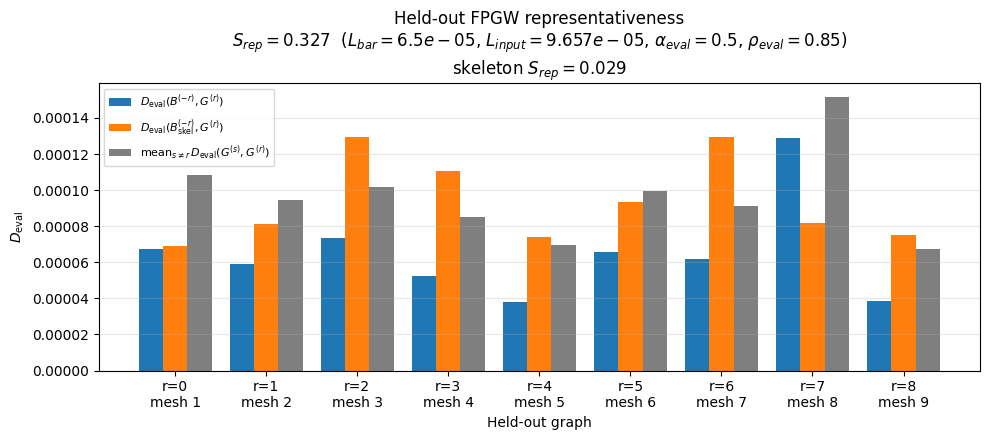

In [6]:
plot_held_out_representativeness(rep, mesh_ids=mesh_ids)


## 2. Held-out edge-evidence Brier skill

This metric does **not** use Metric 1 outputs. It scores the saved candidate barycenter $B=(C,X,\bar\mu)$ against input adjacencies, with correspondences recomputed under a **fixed** evaluation rule.

Let $\pi^{(r)}\in\mathbb{R}_+^{n_B\times n_r}$ be the partial coupling to input $r$, and $K^{(r)}$ that graph's binary adjacency in coupling order. The transported support is

$$
Q^{(r)}=M_B^{-1}\pi^{(r)}K^{(r)}\bigl(\pi^{(r)}\bigr)^\top M_B^{-1},
\qquad
q_{ij}^{(r)}=\frac{\sum_{x,y}\pi_{ix}^{(r)}K_{xy}^{(r)}\pi_{jy}^{(r)}}{\bar\mu_i\bar\mu_j},
$$

with diagonal zeroed. Dividing by $\bar\mu_i\bar\mu_j$ (not matched row masses) treats **occurrence and adjacency together**: an unmatched, absent feature contributes $\approx 0$ rather than abstaining. Then $0\le q_{ij}^{(r)}\le 1$ and $q_{ij}^{(r)}=c_i^{(r)}c_j^{(r)}a_{ij}^{(r)}$.

With equal graph weights the leave-one-out predictor is

$$
p_{ij}^{(-r)}=\frac{1}{m-1}\sum_{s\neq r}q_{ij}^{(s)}.
$$

The weighted Brier score uses $w_{ij}=\bar\mu_i\bar\mu_j$ and the soft held-out target $q^{(r)}$. Skill is relative to a training-only **constant-prevalence** climatology (the weighted mean training support, assigned to every pair):

$$
S_{\mathrm{edge}}=1-\frac{\mathrm{BS}_{\mathrm{edge}}}{\mathrm{BS}_{\mathrm{clim}}}.
$$

$S_{\mathrm{edge}}=1$ is perfect held-out edge probabilities; $0$ matches assigning every pair the same opacity; negative is worse than that baseline. An edge present in two of five inputs under near-deterministic correspondences should have full-sample evidence $\bar q_{ij}=0.4$; setting every opacity to 1 scores poorly.

Held-out $q^{(r)}$ uses fixed $\alpha_{\mathrm{eval}}$ and $\rho_{\mathrm{eval}}$, not the candidate's training $\lambda$ or saved $T_s$. For aligned synthetic data, set `EDGE_CORRESPONDENCE = "spatial"` to replace FPGW by partial OT on $xyz$ (an independent check that FPGW is not rearranging matches to inflate its own evidence).


In [7]:
# Metric 2 config (independent of Metric 1)
EDGE_ALPHA_EVAL = float(alpha_fgw)
EDGE_RHO_EVAL = 0.85
EDGE_CORRESPONDENCE = "mpfgw"  # "mpfgw" or "spatial" (xyz partial OT)
EDGE_MAX_ITER = int(max_iter)
EDGE_CACHE_DIR = Path(BARYCENTER_OUTDIR) / "eval_edge_brier"

if Gs is None or len(Gs) != len(Cs):
    raise RuntimeError("Metric 2 requires bundle['Gs'] aligned with Cs")

print(f"correspondence={EDGE_CORRESPONDENCE}")
print(f"alpha_eval={EDGE_ALPHA_EVAL:g}, rho_eval={EDGE_RHO_EVAL:g}, n_inputs={len(Cs)}")
print(f"cache: {EDGE_CACHE_DIR.resolve()}")


correspondence=mpfgw
alpha_eval=0.5, rho_eval=0.85, n_inputs=9
cache: C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_latest\eval_edge_brier


In [ ]:
edge_brier = compute_held_out_edge_brier(
    C_center,
    X_center,
    p,
    Cs=Cs,
    Ys=Ys,
    ps=ps,
    Gs=Gs,
    nodes_list=nodes_list,
    alpha_eval=EDGE_ALPHA_EVAL,
    rho_eval=EDGE_RHO_EVAL,
    correspondence=EDGE_CORRESPONDENCE,
    graph_weights=None,  # equal weights; pass lambdas to reweight graphs
    gw_restarts=1,
    gw_seed_start=gw_seed_start,
    max_iter=EDGE_MAX_ITER,
    cache_dir=EDGE_CACHE_DIR,
    verbose=True,
)

print(f"\nS_edge = {edge_brier['S_edge']:.4f}")
print(f"BS_edge = {edge_brier['BS_edge']:.6g}")
print(f"BS_clim = {edge_brier['BS_clim']:.6g}")
iu, ju = np.triu_indices(edge_brier["n_center"], k=1)
w_pair = np.asarray(p, dtype=float).reshape(-1)
w_pair = w_pair[iu] * w_pair[ju]
q_bar = edge_brier["q_mean"][iu, ju]
print(
    f"full-sample evidence: mean={float(np.average(q_bar, weights=w_pair)):.4g}, "
    f"max={float(q_bar.max()):.4g}"
)
print("per-fold BS vs climatology:")
for r, (bs, bsc) in enumerate(zip(edge_brier["fold_BS"], edge_brier["fold_BS_clim"])):
    mid = mesh_ids[r] if mesh_ids is not None else r
    print(f"  r={r} mesh {mid}: BS={bs:.6g}, BS_clim={bsc:.6g}")


Eval coupling 1/9 (mpfgw, alpha=0.5, rho=0.85)


c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:754: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  M_gw = gwgrad_partial(C1, C2, Gprev)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:806: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  a = 2.0 * alpha * gwloss_partial(C1, C2, deltaG)
c:\Users\mingz\anaconda3\envs\mscbarycenter\Lib\site-packages\ot\partial\partial_solvers.py:655: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwggrad` instead.
  g = gwgrad_partial(C1, C2, T) * 0.5
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:843: UserWarning: This function will be deprecated in a near future, please use ot.gromov.gwloss` instead.
  dist = (1.0 - alpha) * np.sum(M * G0) + alpha * gwloss_partial(C1, C2, G0)
c:\Users\mingz\desktop\MSCBarycenter\lib\gromov.py:2094: UserWarning: This function will be deprecated in a near future,

Eval coupling 2/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 3/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 4/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 5/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 6/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 7/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 8/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 9/9 (mpfgw, alpha=0.5, rho=0.85)
  graph 0: mean q=0.003936, mean matched fraction=0.8403
  graph 1: mean q=0.003783, mean matched fraction=0.8331
  graph 2: mean q=0.003806, mean matched fraction=0.8423
  graph 3: mean q=0.0039, mean matched fraction=0.8399
  graph 4: mean q=0.003875, mean matched fraction=0.8359
  graph 5: mean q=0.003946, mean matched fraction=0.8394
  graph 6: mean q=0.003962, mean matched fraction=0.8328
  graph 7: mean q=0.003776, mean matched fraction=0.843
  graph 8: mean q=0.003868, mean matched fraction=0.8404
BS_edge=0.000329156, BS_clim=0.00341974, S_edge=0.9037

S_edge = 0.9037
BS_edge = 0.000329156
BS_clim = 0.00341974

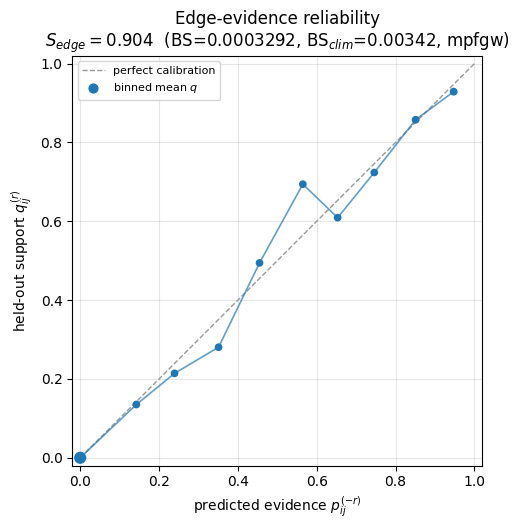

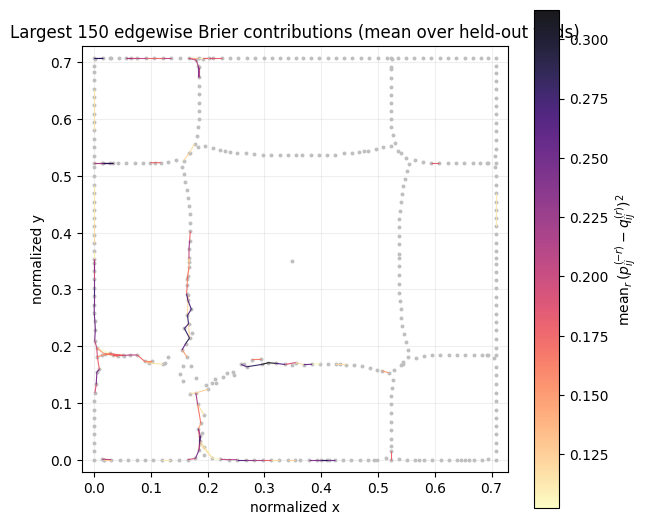

In [9]:
plot_edge_brier_reliability(edge_brier)
plot_edge_brier_error_map(edge_brier, X_center, n_edges=150)


## 3. Morse-valid evidence retention

Independent of Metrics 1 and 2. Ask what fraction of the **evidence-weighted curve length** can coexist in one geometrically and combinatorially plausible Morse graph.

Each candidate edge $e\in E^+$ (pairs with more than negligible evidence $p_e$) has ink $a_e=p_e\ell_e$. Length $\ell_e$ is the displayed Euclidean chord, so regular-point subdivision leaves $\sum p\ell$ unchanged. Then

$$
S_{\mathrm{Morse}}
=\frac{
\max_{F\subseteq E^+,\,F\in\mathcal M}
\sum_{e\in F}p_e\ell_e
}{
\sum_{e\in E^+}p_e\ell_e
}.
$$

The feasible family $\mathcal M$ uses fixed rules:

1. **Geometry:** no interior crossings of nonincident edges; near-overlaps at display resolution are conflicts.
2. **Regular nodes:** degree $\le 2$; degree 2 must be monotone, $(f(u)-f(v))(f(w)-f(v))<0$.
3. **Critical types:** minima only uphill, maxima only downhill, saddles at most two up and two down (degree $\le 4$).
4. **Topology budget:** $\beta_1(F)=|E|-|V|+\beta_0\le b_1^+$ (default $b_1^+=10$). An upper bound, not a target; missing loops are scored by Metrics 1–2.

$S_{\mathrm{Morse}}=1$ means all supported ink fits one valid drawing; $0.88$ means at least 12% conflicts with planarity, local Morse structure, or the cycle budget. A faint shortcut costs little; two high-evidence crossing paths cost a lot.

The optimizer is a **deterministic greedy** (high ink first) plus a 1-add / drop-conflicts **local search**. That is an approximation; the solver name and runtime are reported. The selected subgraph is the explanation: retained edges solid, discarded conflicts translucent.

Edge evidence $p_e$ is the full-sample mean transported support $\frac{1}{m}\sum_r q_{ij}^{(r)}$, recomputed here with fixed evaluation FPGW (not Metric 2 outputs). To reuse Metric 2 couplings, point `MORSE_CACHE_DIR` at that folder.


In [10]:
# Metric 3 config (independent of Metrics 1 and 2)
MORSE_ALPHA_EVAL = float(alpha_fgw)
MORSE_RHO_EVAL = 0.85
MORSE_CORRESPONDENCE = "mpfgw"
MORSE_MAX_ITER = int(max_iter)
MORSE_CACHE_DIR = Path(BARYCENTER_OUTDIR) / "eval_morse"
MORSE_EVIDENCE_EPS = 1e-6
MORSE_MAX_EDGES = 4000
MORSE_B1_PLUS = 10
MORSE_OVERLAP_TOL = 0.002 * float(domain_size)

if Gs is None or len(Gs) != len(Cs):
    raise RuntimeError("Metric 3 requires bundle['Gs'] aligned with Cs")

print("Input cyclomatic numbers (envelope for b1+):")
input_b1 = []
for i, G in enumerate(Gs):
    b1 = int(
        G.number_of_edges()
        - G.number_of_nodes()
        + nx.number_connected_components(G)
    )
    input_b1.append(b1)
    mid = mesh_ids[i] if mesh_ids is not None else i
    print(f"  mesh {mid}: beta1={b1}")
print(
    f"b1+={MORSE_B1_PLUS} (inputs min={min(input_b1)}, max={max(input_b1)})"
)
print(f"alpha_eval={MORSE_ALPHA_EVAL:g}, rho_eval={MORSE_RHO_EVAL:g}")
print(f"cache: {MORSE_CACHE_DIR.resolve()}")


Input cyclomatic numbers (envelope for b1+):
  mesh 1: beta1=9
  mesh 2: beta1=10
  mesh 3: beta1=10
  mesh 4: beta1=9
  mesh 5: beta1=10
  mesh 6: beta1=9
  mesh 7: beta1=9
  mesh 8: beta1=10
  mesh 9: beta1=10
b1+=10 (inputs min=9, max=10)
alpha_eval=0.5, rho_eval=0.85
cache: C:\Users\mingz\desktop\MSCBarycenter\results\barycenters\synthetic_latest\eval_morse


In [ ]:
morse_evidence = barycenter_mean_edge_evidence(
    C_center,
    X_center,
    p,
    Cs=Cs,
    Ys=Ys,
    ps=ps,
    Gs=Gs,
    nodes_list=nodes_list,
    alpha_eval=MORSE_ALPHA_EVAL,
    rho_eval=MORSE_RHO_EVAL,
    correspondence=MORSE_CORRESPONDENCE,
    gw_restarts=1,
    gw_seed_start=gw_seed_start,
    max_iter=MORSE_MAX_ITER,
    cache_dir=MORSE_CACHE_DIR,
    verbose=True,
)

morse = compute_morse_valid_retention(
    X_center,
    evidence=morse_evidence,
    min_x=min_x,
    min_y=min_y,
    min_z=min_z,
    domain_size=domain_size,
    min_scalar=min_scalar,
    scalar_range=scalar_range,
    msc_type_order=MSC_TYPE_ORDER,
    evidence_eps=MORSE_EVIDENCE_EPS,
    max_edges=MORSE_MAX_EDGES,
    b1_plus=MORSE_B1_PLUS,
    overlap_tol=MORSE_OVERLAP_TOL,
    length_mode="euclidean3d",
    local_search=True,
    verbose=True,
)

print(f"\nS_Morse = {morse['S_Morse']:.4f}")
print(
    f"solver={morse['solver']}, optimality={morse['optimality']}, "
    f"{morse['elapsed_sec']:.2f}s, local-search accepts={morse['n_local_search_accepts']}"
)


Eval coupling 1/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 2/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 3/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 4/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 5/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 6/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 7/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 8/9 (mpfgw, alpha=0.5, rho=0.85)
Eval coupling 9/9 (mpfgw, alpha=0.5, rho=0.85)
E+=723 edges, retained=389, beta1=0 (budget 10), conflict pairs=307
S_Morse=0.8593  (ink 6.14555 / 7.15179), solver=greedy+local_search, 14.76s

S_Morse = 0.8593
solver=greedy+local_search, optimality=approximate, 14.76s, local-search accepts=0


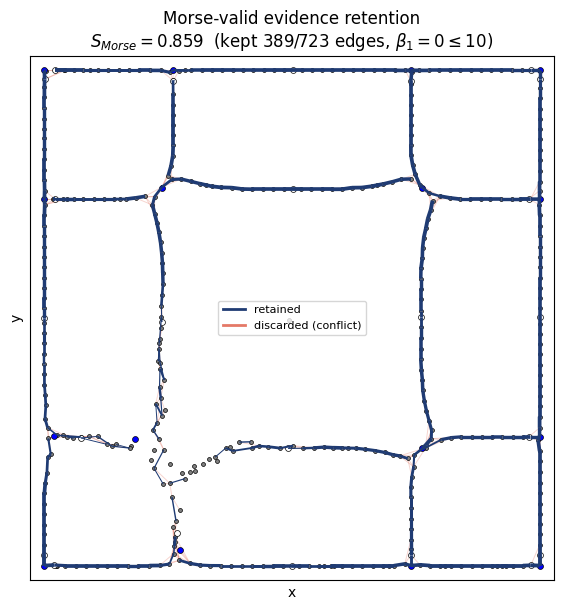

In [ ]:
plot_morse_retention(morse)
